In [13]:
from quantmgmt.data import YahooFinanceData
from quantmgmt.optimizers.black_litterman import black_litterman
from quantmgmt.optimizers.mean_variance import max_sharpe
import numpy as np

### 0. Descarga de datos. Cálculos iniciales.

In [ ]:
import pandas as pd

# Investment Universe – ETFs

etfs = {
    # Equities
    "SPY": ("SPDR S&P 500 ETF Trust", "Equities"),
    "VGK": ("Vanguard FTSE Europe ETF", "Equities"),
    "VWO": ("Vanguard FTSE Emerging Markets ETF", "Equities"),
    "EWJ": ("iShares MSCI Japan ETF", "Equities"),

    # Fixed Income
    "AGG": ("iShares Core U.S. Aggregate Bond ETF", "Fixed Income"),
    "TLT": ("iShares 20+ Year Treasury Bond ETF", "Fixed Income"),
    "IEF": ("iShares 7-10 Year Treasury Bond ETF", "Fixed Income"),
    "LQD": ("iShares iBoxx $ Investment Grade Corporate Bond ETF", "Fixed Income"),
    "TIP": ("iShares TIPS Bond ETF", "Fixed Income"),

    # Commodities
    "GLD": ("SPDR Gold Shares", "Commodities"),
    "DBC": ("Invesco DB Commodity Index Tracking Fund", "Commodities")
}
names = [n[0] for n in etfs.values()]

# Asset allocation
market_weights = {
    "SPY": 0.15,
    "VGK": 0.15,
    "VWO": 0.15,
    "EWJ": 0.15,
    "AGG": 0.06,
    "TLT": 0.06,
    "IEF": 0.06,
    "LQD": 0.06,
    "TIP": 0.06,
    "GLD": 0.05,
    "DBC": 0.05
}

# Create DataFrame
universe_df = pd.DataFrame([
    {
        "Ticker": ticker,
        "ETF Name": name,
        "Asset Class": asset_class,
        "Weight": market_weights[ticker]
    }
    for ticker, (name, asset_class) in etfs.items()
])

print("INVESTMENT UNIVERSE: Strategic Benchmark Portfolio")
print("=" * 100)
display(universe_df)
print("=" * 100)
print(f"Number of assets: {len(universe_df)}")

INVESTMENT UNIVERSE: Strategic Benchmark Portfolio


,Ticker,ETF Name,Asset Class,Weight
0,SPY,SPDR S&P 500 ETF Trust,Equities,0.15
1,VGK,Vanguard FTSE Europe ETF,Equities,0.15
2,VWO,Vanguard FTSE Emerging Markets ETF,Equities,0.15
3,EWJ,iShares MSCI Japan ETF,Equities,0.15
4,AGG,iShares Core U.S. Aggregate Bond ETF,Fixed Income,0.06
5,TLT,iShares 20+ Year Treasury Bond ETF,Fixed Income,0.06
6,IEF,iShares 7-10 Year Treasury Bond ETF,Fixed Income,0.06
7,LQD,iShares iBoxx $ Investment Grade Corporate Bon...,Fixed Income,0.06
8,TIP,iShares TIPS Bond ETF,Fixed Income,0.06
9,GLD,SPDR Gold Shares,Commodities,0.05


Number of assets: 11


Hemos elegido el universo anterior fundamentalmente por el hecho de que es más o menos representativo de una cartera diversificada y porque pensamos que tener varios Asset Class puede ser más interesante a la hora de interpretar los resultados de los diferentes optimizadores que si solamente tenemos Equities.

In [15]:
# Descarga 
TICKERS = [
    "SPY", "VGK", "VWO", "EWJ",
    "AGG", "TLT", "IEF", "LQD", "TIP",
    "GLD", "DBC"
]
START, END = "2014-01-01", "2025-12-31"

loader = YahooFinanceData()
assets = loader.get_prices(TICKERS, START, END)[TICKERS]

In [16]:
# Cálculos iniciales:
returns = assets.pct_change().dropna()
w_mkt = [w for w in market_weights.values()]
sigma = returns.cov() * 252
sigma_daily = returns.cov()
corr = returns.corr()

## Parte A: Black-Litterman

### 1. Pesos de equilibrio

### 2. Optimización inversa

In [17]:
market_returns = returns @ np.array(w_mkt)
delta = (market_returns.mean() * 252)/(market_returns.var() * 252)

In [18]:
pi_equilibrium = delta * sigma @ w_mkt
pi_equilibrium

SPY    0.101534
VGK    0.112429
VWO    0.113578
EWJ    0.097778
AGG    0.011160
TLT    0.004000
IEF    0.003425
LQD    0.025052
TIP    0.010051
GLD    0.026654
DBC    0.052166
dtype: float64

### 3. Visiones

Para este apartado, hemos analizado por encima el entorno macroeconómico. La idea es la de poder dar una opinión fundada sobre las views del ejercicio, no necesariamente acertar o predecir movimientos en los activos.

- **Crecimiento global:** La economía mundial mantiene un crecimiento moderado, aunque desigual entre regiones. El FMI estima un crecimiento del 3,1% en 2026.

- **Estados Unidos:** La economía muestra resiliencia, con un crecimiento relativamente sólido, pero la inflación sigue por encima del objetivo del 2% de la Reserva Federal.

- **Política monetaria:** La persistencia de las presiones inflacionistas limita el margen de los bancos centrales para reducir los tipos de interés, generando incertidumbre sobre su evolución.

- **Europa:** Presenta un crecimiento económico débil, condicionado por los elevados costes energéticos y la incertidumbre geopolítica.

- **Mercados emergentes:** Mantienen perspectivas de crecimiento relativamente favorables, aunque con importantes diferencias entre países y exposición a riesgos comerciales y cambiarios.

- **Japón:** Está experimentando mayores presiones inflacionistas y salariales, en un contexto de normalización económica y monetaria.

- **Materias primas:** Las tensiones geopolíticas, especialmente en Oriente Medio, incrementan la incertidumbre sobre los precios energéticos y pueden alimentar nuevas presiones inflacionistas.

- **Incertidumbre global:** Los conflictos geopolíticos, las tensiones comerciales y la persistencia de la inflación constituyen los principales riesgos para los mercados financieros, favoreciendo potencialmente la demanda de activos defensivos como el oro.

Con estas ideas en la mesa, podemos proponer algunas views:
1. Europa se encuentra últimamente algo lagging en cuanto a crecimiento y parece que se acercará a un escenario de estanflación más acuciantemente que Estados Unidos. La rentabilidad de los últimos 20 años del Vanguard FTSE Europe ETF ha sido un 3,70%. La del SPDR S&P 500 ETF Trust ha sido un 7.80% anual. Creemos que puede ampliarse este spread alrededor de un 1% más aproximadamente. Por lo tanto:

E[SPY] - E[VGK] = 5.00%

2. El oro puede continuar viéndose como activo refugio si las políticas de los bancos centrales de subidas de tipos no consiguen controlar la inflación. La rentabilidad que puede estar dando este año, será parecida a la histórica, digamos un 3.5%. La del oro, quizás algo superior de lo habitual, digamos un 8%. Entonces:

E[GLD] - E[TLT] = 4.50%

3. Por último es posible que los conflictos que están actualmente moviendo los mercados de commodities cesen o al menos se calmen basten durante el próximo año, por lo que esperamos una caída relativa de los índices de commodities con respecto al oro de:

E[DBC] - E[GLD] = -8.00%

In [19]:
P = np.array([
    [1, -1, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0,  0, 0, 0, 0, -1, 0, 0, 0, 1, 0],
    [0,  0, 0, 0, 0,  0, 0, 0, 0, -1, 1]
])
Q = np.array([
    0.05,
    0.045,
    -0.08
])

tau = 0.05

In [20]:
varianza_views = P@(tau * sigma)@P.transpose()
varianza_views

,0,1,2
0,0.000607,-0.000105,0.000062
1,-0.000105,0.001575,-0.000245
2,0.000062,-0.000245,0.001892


In [21]:
returns_bl = black_litterman(pi = pi_equilibrium, sigma = sigma, P = P, Q = Q, tau = tau)
w_bl = max_sharpe(returns_bl[0], sigma)
w_bl.sum()

np.float64(1.0)

In [22]:
df_comparación_pesos = pd.DataFrame()
df_comparación_pesos["Tickers"] = TICKERS
df_comparación_pesos["Nombres"] = names
df_comparación_pesos["Pesos Cartera"] = w_mkt
df_comparación_pesos["Peso Black Litterman"] = np.round(w_bl, 2)
print("====== COMPARACIÓN: PESOS DE LA CARTERA VS. PESOS BLACK LITTERMAN ======")
df_comparación_pesos

====== COMPARACIÓN: PESOS DE LA CARTERA VS. PESOS BLACK LITTERMAN ======


,Tickers,Nombres,Pesos Cartera,Peso Black Litterman
0,SPY,"(SPDR S&P 500 ETF Trust, Equities)",0.15,0.42
1,VGK,"(Vanguard FTSE Europe ETF, Equities)",0.15,0.00
2,VWO,"(Vanguard FTSE Emerging Markets ETF, Equities)",0.15,0.04
3,EWJ,"(iShares MSCI Japan ETF, Equities)",0.15,0.09
4,AGG,"(iShares Core U.S. Aggregate Bond ETF, Fixed I...",0.06,0.00
5,TLT,"(iShares 20+ Year Treasury Bond ETF, Fixed Inc...",0.06,0.07
6,IEF,"(iShares 7-10 Year Treasury Bond ETF, Fixed In...",0.06,0.14
7,LQD,(iShares iBoxx $ Investment Grade Corporate Bo...,0.06,0.00
8,TIP,"(iShares TIPS Bond ETF, Fixed Income)",0.06,0.00
9,GLD,"(SPDR Gold Shares, Commodities)",0.05,0.24


In [23]:
print("====== COMPARACIÓN: RETORNOS DE EQUILIBRIO ======")
df_returns = pd.DataFrame({
    "Ticker": TICKERS,
    "Equilibrio": pi_equilibrium,
    "Black_Litterman": returns_bl[0]
})

df_returns.round(4)

====== COMPARACIÓN: RETORNOS DE EQUILIBRIO ======


,Ticker,Equilibrio,Black_Litterman
SPY,SPY,0.1015,0.1008
VGK,VGK,0.1124,0.0825
VWO,VWO,0.1136,0.0953
EWJ,EWJ,0.0978,0.0859
AGG,AGG,0.0112,0.0123
TLT,TLT,0.0040,0.0118
IEF,IEF,0.0034,0.0074
LQD,LQD,0.0251,0.0264
TIP,TIP,0.0101,0.0101
GLD,GLD,0.0267,0.0464


In [24]:
views_posterior = P @ returns_bl[0]

pd.DataFrame({
    "View": Q,
    "Posterior": views_posterior,
    "Difference": views_posterior - Q
}).round(4)

,View,Posterior,Difference
0,0.050,0.0183,-0.0317
1,0.045,0.0346,-0.0104
2,-0.080,-0.0264,0.0536


## Parte B: Heriarchical Risk Parity

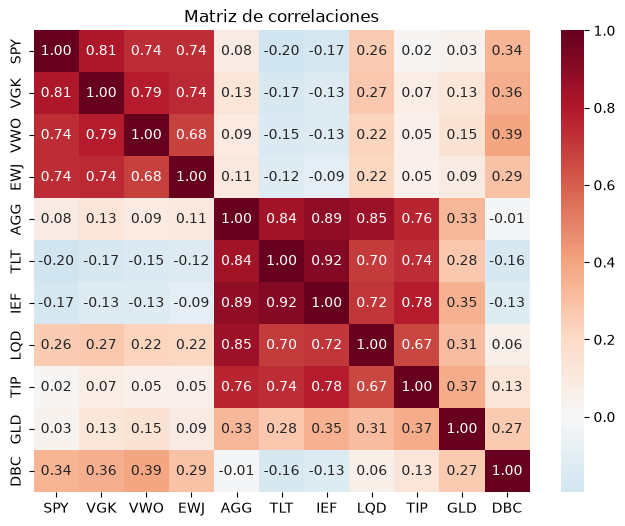

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt
from quantmgmt.optimizers.hrp import distance_correlation
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram
from quantmgmt.optimizers.black_litterman import get_hrp_weights, risk_contribution, get_risk_parity_naive_weights


plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, fmt=".2f")
plt.title("Matriz de correlaciones")
plt.show()

Aquí no es que hayamos aplicado aún la cuasi-diagonalización, es solamente que el orden en que hemos cargados los tickers al inicio corresponde a la divisón por asset class, por eso aparece naturalmente esta matriz de correlaciones.

In [26]:
# Cálculo del dendrograma
dist_corr = distance_correlation(corr)
dist_assets = pdist(dist_corr.T, metric="euclidean")
Z = linkage(dist_assets, method="ward")

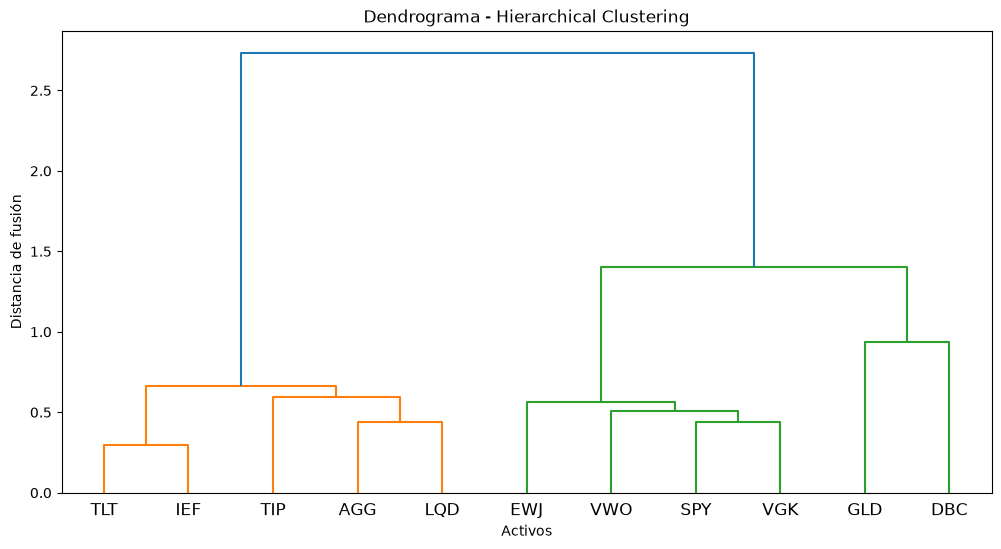

In [27]:
# Plot del dendrograma
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    labels=TICKERS
)

plt.title("Dendrograma - Hierarchical Clustering")
plt.xlabel("Activos")
plt.ylabel("Distancia de fusión")
plt.show()

In [28]:
from scipy.cluster.hierarchy import leaves_list
orden = leaves_list(Z)
corr_ordenada = corr.iloc[orden, orden]

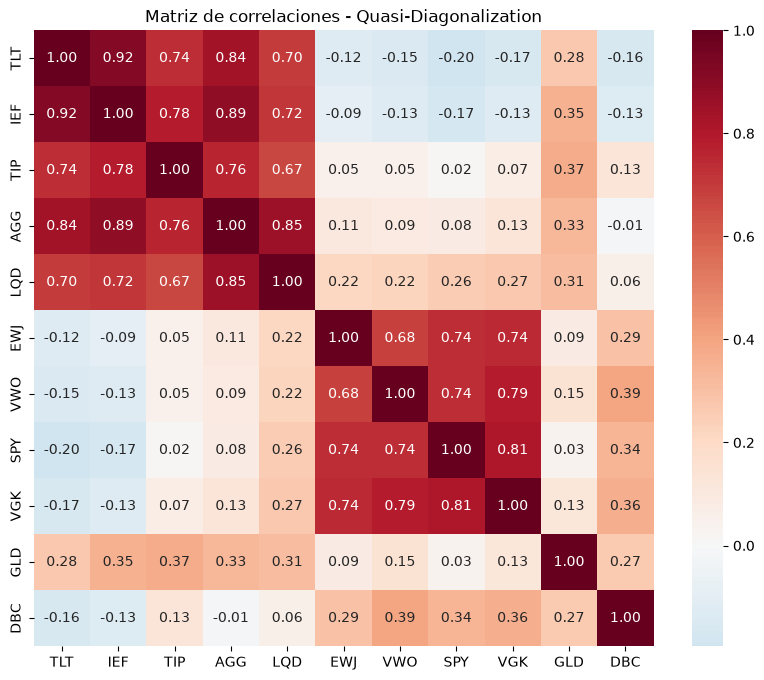

In [29]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_ordenada,
    annot=True,
    cmap="RdBu_r",
    center=0,
    fmt=".2f"
)

plt.title("Matriz de correlaciones - Quasi-Diagonalization")
plt.show()

In [30]:
print("=== Pesos de la cartera usando HRP ===")
weights_hrp = get_hrp_weights(sigma, orden)
weights_hrp

=== Pesos de la cartera usando HRP ===


TLT    0.043681
IEF    0.223635
TIP    0.278228
AGG    0.195774
LQD    0.075609
EWJ    0.031136
VWO    0.014274
SPY    0.017698
VGK    0.038051
GLD    0.047180
DBC    0.034735
dtype: float64

In [31]:
weights_hrp = weights_hrp.reindex(sigma.index)

rc_hrp = risk_contribution(weights_hrp.values, sigma.values)
df_rc_hrp = pd.DataFrame(data={"Tickers": TICKERS, "Contribuciones al riesgo":rc_hrp})
df_rc_hrp


,Tickers,Contribuciones al riesgo
0,SPY,0.015831
1,VGK,0.045326
2,VWO,0.015893
3,EWJ,0.031320
4,AGG,0.160400
5,TLT,0.087784
6,IEF,0.214044
7,LQD,0.094473
8,TIP,0.244951
9,GLD,0.063975


In [32]:
weights_rp_naive = get_risk_parity_naive_weights(sigma)
rc_rp_naive = risk_contribution(
    weights_rp_naive.values,
    sigma.values
)
df_comparaciones = pd.DataFrame({
    "HRP Weight": weights_hrp,
    "HRP Risk Contribution": rc_hrp,
    "Naive RP Weight": weights_rp_naive,
    "Naive RP Risk Contribution": rc_rp_naive
})

df_comparaciones = df_comparaciones.sort_values(
    "HRP Risk Contribution",
    ascending=False
)
df_comparaciones

,HRP Weight,HRP Risk Contribution,Naive RP Weight,Naive RP Risk Contribution
TIP,0.278228,0.244951,0.165812,0.106434
IEF,0.223635,0.214044,0.144319,0.091535
AGG,0.195774,0.160400,0.184719,0.116041
LQD,0.075609,0.094473,0.114794,0.120712
TLT,0.043681,0.087784,0.063782,0.083871
GLD,0.047180,0.063975,0.063665,0.075567
VGK,0.038051,0.045326,0.050875,0.091860
EWJ,0.031136,0.031320,0.054554,0.084486
DBC,0.034735,0.026003,0.054627,0.058225
VWO,0.014274,0.015893,0.048665,0.087707


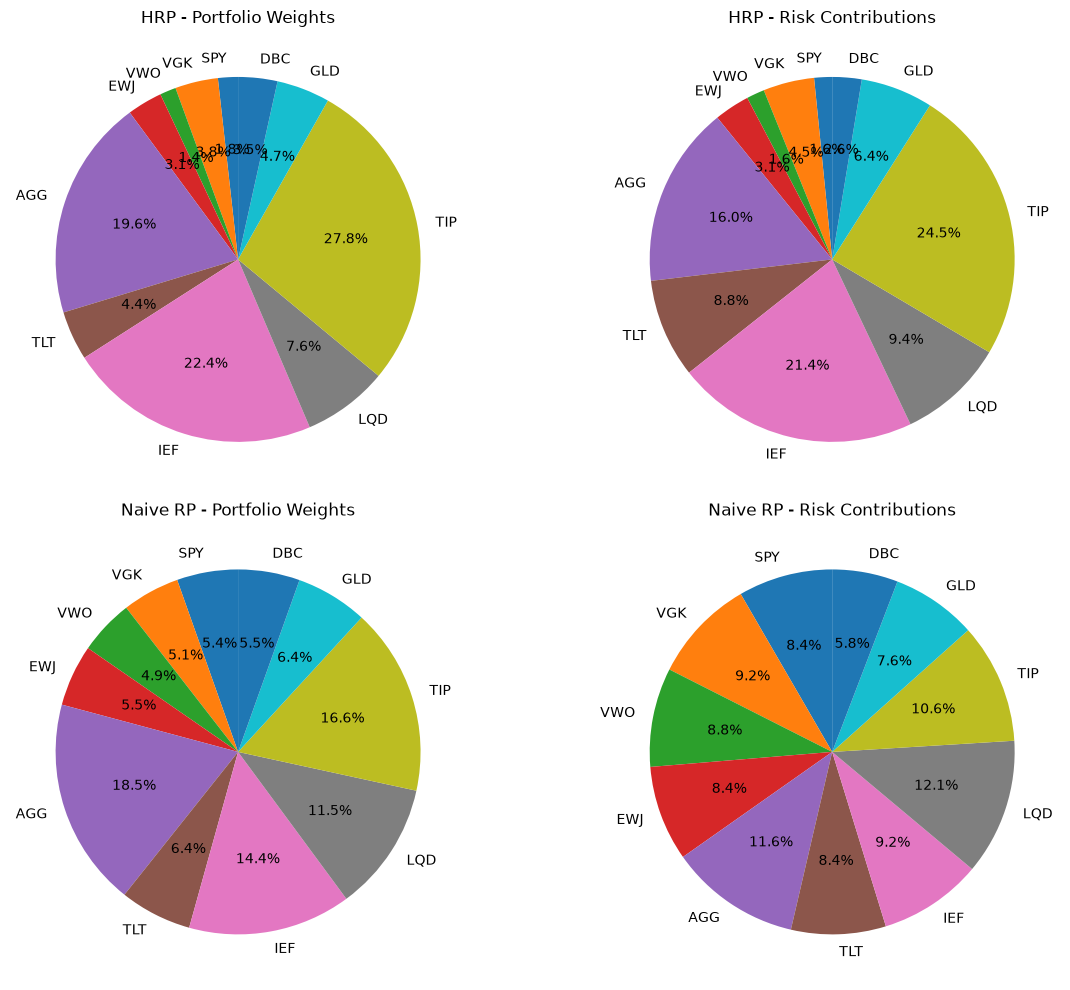

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. HRP Weights
axes[0, 0].pie(
    weights_hrp.values,
    labels=weights_hrp.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[0, 0].set_title("HRP - Portfolio Weights")

# 2. HRP Risk Contributions
axes[0, 1].pie(
    rc_hrp,
    labels=TICKERS,
    autopct="%1.1f%%",
    startangle=90
)
axes[0, 1].set_title("HRP - Risk Contributions")

# 3. Naive RP Weights
axes[1, 0].pie(
    weights_rp_naive.values,
    labels=weights_rp_naive.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 0].set_title("Naive RP - Portfolio Weights")

# 4. Naive RP Risk Contributions
axes[1, 1].pie(
    rc_rp_naive,
    labels=TICKERS,
    autopct="%1.1f%%",
    startangle=90
)
axes[1, 1].set_title("Naive RP - Risk Contributions")

plt.tight_layout()
plt.show()

### Comparación entre HRP y Naive Risk Parity

La cartera HRP presenta una elevada concentración en renta fija (81,7%), especialmente en iShares TIPS Bond ETF (27,82%), iShares 7-10 Year Treasury Bond ETF (22,36%) e iShares Core U.S. Aggregate Bond ETF (19,58%). Esta asignación refleja la lógica del algoritmo: durante el proceso de bisección recursiva, los clústeres con menor varianza agregada reciben una mayor ponderación. Por tanto, la elevada exposición a renta fija sugiere que la estructura de riesgo y correlaciones de estos activos ha favorecido su asignación frente a otros grupos.

Por el contrario, los ETF de renta variable y materias primas reciben pesos considerablemente menores. Esto puede estar relacionado con su mayor volatilidad y con la estructura de correlaciones que presentan entre sí y respecto al resto de activos. No obstante, es importante destacar que se puede comprobar que HRP no considera únicamente la volatilidad individual de cada ETF, sino también las relaciones de dependencia entre los activos y la varianza agregada de los distintos clústeres. Esto explica, por ejemplo, que existan diferencias significativas de ponderación entre fondos de una misma asset class, como iShares 7-10 Year Treasury Bond ETF (22,36%) e iShares 20+ Year Treasury Bond ETF (4,37%).

## Parte C: Comparaciones entre Carteras

In [34]:
from quantmgmt.optimizers.mean_variance import (
    estimate_inputs,
    min_variance,
    max_sharpe,
    Constraints
)

from quantmgmt.optimizers.black_litterman import (
    black_litterman,
    get_hrp_weights,
    risk_contribution,
    get_risk_parity_naive_weights
)


In [35]:
YEARS_VENTANA_ESTIMACION = 3

# Primera fecha posible de evaluación fuera de muestra
primera_fecha_oos = (
    returns.index[0] + pd.DateOffset(years=YEARS_VENTANA_ESTIMACION)
)

# Primer día de cotización de cada trimestre
fechas_rebalanceo_trimestral = (
    returns.groupby(returns.index.to_period("Q"))
    .apply(lambda datos_trimestre: datos_trimestre.index[0])
)

# Conservar únicamente las fechas con al menos 3 años de historia
fechas_rebalanceo = fechas_rebalanceo_trimestral[
    fechas_rebalanceo_trimestral >= primera_fecha_oos
].tolist()


# ============================================================
# CONSTRUCCIÓN DE VENTANAS DE ESTIMACIÓN Y EVALUACIÓN
# ============================================================

ventanas_backtest = []

for i, fecha_rebalanceo in enumerate(fechas_rebalanceo):

    # --------------------------------------------------------
    # Ventana de estimación: 3 años anteriores al rebalanceo
    # --------------------------------------------------------

    fecha_inicio_estimacion = (
        fecha_rebalanceo - pd.DateOffset(years=YEARS_VENTANA_ESTIMACION)
    )

    rentabilidades_estimacion = returns.loc[
        (returns.index >= fecha_inicio_estimacion) &
        (returns.index < fecha_rebalanceo)
    ]

    # --------------------------------------------------------
    # Ventana fuera de muestra: siguiente trimestre
    # --------------------------------------------------------

    if i < len(fechas_rebalanceo) - 1:

        siguiente_fecha_rebalanceo = fechas_rebalanceo[i + 1]

        rentabilidades_oos = returns.loc[
            (returns.index > fecha_rebalanceo) &
            (returns.index <= siguiente_fecha_rebalanceo)
        ]

    else:
        # Último periodo: hasta la última fecha disponible

        rentabilidades_oos = returns.loc[
            returns.index > fecha_rebalanceo
        ]

    # Guardar información del periodo
    ventanas_backtest.append({
        "fecha_rebalanceo": fecha_rebalanceo,
        "rentabilidades_estimacion": rentabilidades_estimacion,
        "rentabilidades_oos": rentabilidades_oos
    })

In [36]:
def calcular_pesos_equiponderados(rentabilidades):
    numero_activos = rentabilidades.shape[1]
    pesos = np.repeat(1 / numero_activos, numero_activos)
    return pd.Series(pesos, index=rentabilidades.columns)

In [37]:
def calcular_pesos_carteras(rentabilidades_estimacion):

    # Estimar rentabilidades y covarianzas anualizadas
    mu, cov = estimate_inputs(
        rentabilidades_estimacion,
        periods_per_year=252
    )

    restricciones = Constraints(long_only=True)
    numero_activos = len(rentabilidades_estimacion.columns)

    # 1. Equal Weight
    pesos_equal_weight = calcular_pesos_equiponderados(
        rentabilidades_estimacion
    )

    # 2. Minimum Variance
    pesos_min_variance = min_variance(
        cov,
        constraints=restricciones
    )

    # 3. Maximum Sharpe
    pesos_max_sharpe = max_sharpe(
        mu,
        cov,
        risk_free_rate=0.0,
        constraints=restricciones
    )

    # 4. Black-Litterman

    # Pesos de equilibrio
    pesos_mkt = pd.Series(market_weights).reindex(cov.index)

    # Rentabilidad de la cartera de mercado
    rentabilidad_mercado = rentabilidades_estimacion @ pesos_mkt

    # Aversión al riesgo implícita
    delta = rentabilidad_mercado.mean() / rentabilidad_mercado.var()

    # Rentabilidades implícitas de equilibrio
    pi = delta * (cov @ pesos_mkt)

    # Incorporar las visiones de la Parte A
    mu_bl, cov_bl = black_litterman(
        pi=pi.values,
        sigma=cov.values,
        P=P,
        Q=Q,
        tau=tau
    )

    mu_bl = pd.Series(mu_bl, index=cov.index)

    # Optimización de la cartera Black-Litterman
    pesos_bl = max_sharpe(
        mu_bl,
        cov,
        risk_free_rate=0.0,
        constraints=restricciones
    )

    # 5. HRP

    # Correlaciones estimadas en la ventana
    correlaciones = rentabilidades_estimacion.corr()

    # Distancia basada en correlaciones
    dist_corr = distance_correlation(correlaciones)

    # Clustering jerárquico
    dist_activos = pdist(
        dist_corr.T,
        metric="euclidean"
    )

    Z = linkage(
        dist_activos,
        method="ward"
    )

    # Cuasi-diagonalización
    orden = leaves_list(Z)

    # Asignación de pesos HRP
    pesos_hrp = get_hrp_weights(cov, orden)

    # Resultado
    return {
        "Equal Weight": pesos_equal_weight,
        "Minimum Variance": pesos_min_variance,
        "Maximum Sharpe": pesos_max_sharpe,
        "Black-Litterman": pesos_bl,
        "HRP": pesos_hrp
    }

In [38]:
# ============================================================
# BACKTEST FUERA DE MUESTRA
# ============================================================

resultados_backtest = {
    "Equal Weight": [],
    "Minimum Variance": [],
    "Maximum Sharpe": [],
    "Black-Litterman": [],
    "HRP": []
}

pesos_historicos = {
    nombre: []
    for nombre in resultados_backtest
}

for ventana in ventanas_backtest:

    fecha_rebalanceo = ventana["fecha_rebalanceo"]
    rentabilidades_estimacion = ventana["rentabilidades_estimacion"]
    rentabilidades_oos = ventana["rentabilidades_oos"]

    # Calcular los pesos utilizando exclusivamente
    # la información disponible en la ventana de estimación
    pesos_carteras = calcular_pesos_carteras(
        rentabilidades_estimacion
    )

    # Aplicar los pesos durante el siguiente trimestre
    for nombre, pesos in pesos_carteras.items():

        pesos = pesos.reindex(returns.columns)

        rentabilidad_cartera = (
            rentabilidades_oos @ pesos
        )

        resultados_backtest[nombre].append(
            rentabilidad_cartera
        )

        pesos_historicos[nombre].append({
            "fecha": fecha_rebalanceo,
            "pesos": pesos
        })


# Unir las rentabilidades de todos los trimestres
rentabilidades_backtest = pd.DataFrame({
    nombre: pd.concat(periodos).sort_index()
    for nombre, periodos in resultados_backtest.items()
})

display(rentabilidades_backtest.head())
print("\nFecha inicial:", rentabilidades_backtest.index.min())
print("Fecha final:", rentabilidades_backtest.index.max())
print("Número de observaciones:", len(rentabilidades_backtest))

,Equal Weight,Minimum Variance,Maximum Sharpe,Black-Litterman,HRP
Date,,,,,
2017-01-04,0.005961,0.001019,0.001471,0.004792,0.002555
2017-01-05,0.007285,0.003775,0.003542,0.008245,0.005424
2017-01-06,-0.003820,-0.002676,-0.002160,-0.002637,-0.004125
2017-01-09,0.000243,0.000792,0.000894,0.003063,0.001634
2017-01-10,0.000004,-0.000379,-0.000235,0.001906,-0.000142



Fecha inicial: 2017-01-04 00:00:00
Fecha final: 2025-12-30 00:00:00
Número de observaciones: 2260


In [39]:
# ============================================================
# CONSTRUIR ÍNDICES DE LAS CARTERAS
# ============================================================

# Convertir las rentabilidades diarias en índices con base 100
indices_backtest = 100 * (1 + rentabilidades_backtest).cumprod()

display(indices_backtest.head())

,Equal Weight,Minimum Variance,Maximum Sharpe,Black-Litterman,HRP
Date,,,,,
2017-01-04,100.596092,100.101902,100.147108,100.479222,100.255480
2017-01-05,101.328919,100.479786,100.501844,101.307691,100.799222
2017-01-06,100.941848,100.210925,100.284731,101.040528,100.383423
2017-01-09,100.966368,100.290259,100.374360,101.350040,100.547483
2017-01-10,100.966802,100.252242,100.350800,101.543243,100.533157


In [40]:
# ============================================================
# MÉTRICAS DE RENDIMIENTO Y RIESGO
# ============================================================

from quantmgmt.risk import (
    annualized_return,
    annualized_volatility,
    sharpe_ratio,
    sortino_ratio,
    max_drawdown,
    calmar_ratio
)

metricas_backtest = pd.DataFrame(index=indices_backtest.columns)

metricas_backtest["Annualized Return"] = annualized_return(
    indices_backtest,
    periods_per_year=252
)

metricas_backtest["Annualized Volatility"] = annualized_volatility(
    indices_backtest,
    periods_per_year=252
)

metricas_backtest["Sharpe Ratio"] = sharpe_ratio(
    indices_backtest,
    periods_per_year=252,
    risk_free_rate=0.0
)

metricas_backtest["Sortino Ratio"] = sortino_ratio(
    indices_backtest,
    periods_per_year=252,
    risk_free_rate=0.0
)

metricas_backtest["Maximum Drawdown"] = max_drawdown(
    indices_backtest
)

metricas_backtest["Calmar Ratio"] = calmar_ratio(
    indices_backtest,
    periods_per_year=252
)

display(metricas_backtest.round(4))

,Annualized Return,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio
Equal Weight,0.0707,0.0836,0.8464,1.1823,-0.1943,0.3578
Minimum Variance,0.0269,0.0561,0.4799,0.6516,-0.1702,0.1508
Maximum Sharpe,0.0778,0.0968,0.8038,1.1437,-0.1854,0.4091
Black-Litterman,0.1256,0.1070,1.1739,1.6932,-0.2078,0.6125
HRP,0.0416,0.0605,0.6883,0.9737,-0.1764,0.2302


In [41]:
# ============================================================
# ROTACIÓN Y CONCENTRACIÓN
# ============================================================

resultados_estructura = []

for nombre, historial in pesos_historicos.items():

    # Recuperar los pesos de cada rebalanceo
    matriz_pesos = pd.DataFrame(
        [registro["pesos"] for registro in historial],
        index=[registro["fecha"] for registro in historial]
    )

    # Número efectivo de activos
    numero_efectivo = 1 / (matriz_pesos ** 2).sum(axis=1)

    # Rotación trimestral
    rotacion_trimestral = (
        matriz_pesos.diff().abs().sum(axis=1) / 2
    ).dropna()

    resultados_estructura.append({
        "Portfolio": nombre,
        "Effective Number of Assets": numero_efectivo.mean(),
        "Average Annual Turnover": rotacion_trimestral.mean() * 4
    })

metricas_estructura = (
    pd.DataFrame(resultados_estructura)
    .set_index("Portfolio")
)

display(metricas_estructura.round(4))

,Effective Number of Assets,Average Annual Turnover
Portfolio,,
Equal Weight,11.0000,0.0000
Minimum Variance,1.7774,0.3038
Maximum Sharpe,1.9722,0.7727
Black-Litterman,3.3078,0.4799
HRP,5.3345,0.1693


### Conclusión:

Aunque Black-Litterman obtiene el mayor Sharpe fuera de muestra (1,17), sus resultados deben interpretarse con cautela. Las visiones incorporadas al modelo (las views) se formularon para hacer el ejercicio, es decir, para ponernos nosotros en la piel de un portfolio manager en 2026 y, por lo tanto, las views corresponden a ese año. Por ello, aplicarlas de manera retrospectiva a todo el periodo 2017–2025 de esta segunda parte no nos tiene sentido, dado que habría que hacer un backtest, también, incorporando las views al proceso (lo cual es inviable para la práctica). Por tanto, su rendimiento no es directamente comparable con el de las demás estrategias desde el punto de vista de su implementabilidad histórica. 

En cuanto al resto de estrategias, Equal Weight obtiene resultados bastante competitivos, con un Sharpe de 0,85. Destaca especialmente por su diversificación (evidentemente por mantener los 11 activos con el mismo peso), y por no necesitar rebalanceos, lo que elimina la rotación y los costes asociados. Esto demuestra que una estrategia sencilla podría competir con métodos de optimización más sofisticados.

Minimum Variance consigue la menor volatilidad (5,61%), pero a costa de una rentabilidad anualizada muy reducida (2,69%). Esto se debe a que concentra gran parte del capital en un número muy reducido de activos (1,78 activos efectivos), priorizando la reducción del riesgo frente a la generación de rentabilidad. No parece que compense tampoco por temas de Drawdown, ya que incluso en esta métrica, que esperaríamos que fuera bastante baja, tampoco gana.

Maximum Sharpe alcanza una rentabilidad atractiva (7,78%), pero presenta una concentración elevada (1,97 activos efectivos) y la mayor rotación anual (77,27%). Esto refleja la sensibilidad de la optimización media-varianza a los errores de estimación de las rentabilidades esperadas, que pueden provocar cambios importantes en las ponderaciones entre rebalanceos.

Por último, HRP ofrece una alternativa más diversificada, con 5,33 activos efectivos y una rotación anual de solo el 16,93%. Su volatilidad relativamente baja (6,05%) es coherente con su enfoque basado en la estructura de correlaciones y la asignación jerárquica del riesgo. Sin embargo, esta mayor estabilidad no se traduce necesariamente en una mayor rentabilidad, que se queda en el 4,16% anualizado.

-------------------

En conjunto, Equal Weight y HRP destacan por su diversificación y estabilidad, mientras que Minimum Variance prioriza la reducción del riesgo y Maximum Sharpe busca una mayor rentabilidad asumiendo una concentración y rotación superiores. No creemos que se pueda concluir que una cartera es estrictamente superior a otra, sinceramente. Si ordenamos por Sharpe (descontando Black-Litterman por lo que ya habíamos comentado) tenemos que Equal Weight y Maximum Sharpe son las mejores. En cualquier caso, Equal Weight, es la menos idiosincrásica y más robusta así que, paradójicamente, probablemente Equal Weight sea la más sensata de todas las distribuciones de pesos.